# BharatMarket AI
## Notebook 04: Time Series Analysis

**Course:** CS3216 - Time Series Analysis and Forecasting

### Objectives

1. Analyse time-series trends.
2. Identify trend, seasonal and residual components.
3. Study additive and multiplicative decomposition.
4. Test stationarity using the Augmented Dickey-Fuller test.
5. Apply first-order and second-order differencing.
6. Analyse ACF and PACF.
7. Study volatility clustering.
8. Prepare the datasets for ARIMA and SARIMA forecasting.

### Primary Instruments
- NIFTY 50
- BANK NIFTY
- Eight NSE-listed companies.

### Frequency
Daily market observations.

In [1]:
# ============================================
# CELL 1: IMPORT LIBRARIES
# ============================================

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from IPython.display import display

sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (14, 6)

print("BharatMarket AI")
print("Time Series Analysis")
print("Libraries imported successfully!")

BharatMarket AI
Time Series Analysis
Libraries imported successfully!


In [2]:
# ============================================
# CELL 2: PROJECT CONFIGURATION
# ============================================

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

FEATURE_DATA_DIR = PROJECT_DIR / "data" / "features"

OUTPUT_DIR = PROJECT_DIR / "outputs"

CHART_DIR = OUTPUT_DIR / "charts"
REPORT_DIR = OUTPUT_DIR / "reports"

CHART_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

INSTRUMENTS = {
    "NIFTY50": "NIFTY 50",
    "BANKNIFTY": "BANK NIFTY",
    "RELIANCE": "Reliance Industries",
    "TCS": "Tata Consultancy Services",
    "HDFCBANK": "HDFC Bank",
    "INFY": "Infosys",
    "ICICIBANK": "ICICI Bank",
    "SBIN": "State Bank of India",
    "ITC": "ITC Limited",
    "LT": "Larsen & Toubro"
}

print("Project paths configured.")

Project paths configured.


In [3]:
# ============================================
# CELL 3: LOAD FEATURE DATASETS
# ============================================

market_data = {}

for symbol, company in INSTRUMENTS.items():

    file_path = (
        FEATURE_DATA_DIR /
        f"{symbol}_features_full.csv"
    )

    if not file_path.exists():
        print("Missing:", file_path)
        continue

    df = pd.read_csv(file_path)

    df["date"] = pd.to_datetime(df["date"])

    df = (
        df.sort_values("date")
        .drop_duplicates("date", keep="last")
        .set_index("date")
    )

    market_data[symbol] = df

    print(f"{symbol}: {len(df)} observations loaded")

print("\nTotal datasets:", len(market_data))

assert len(market_data) == 10, (
    "Please check Notebook 03 feature exports."
)

NIFTY50: 1236 observations loaded
BANKNIFTY: 1235 observations loaded
RELIANCE: 1237 observations loaded
TCS: 1237 observations loaded
HDFCBANK: 1237 observations loaded
INFY: 1237 observations loaded
ICICIBANK: 1237 observations loaded
SBIN: 1237 observations loaded
ITC: 1237 observations loaded
LT: 1237 observations loaded

Total datasets: 10


In [4]:
# ============================================
# CELL 4: PREPARE TIME SERIES
# ============================================

price_series = {}
return_series = {}

for symbol, df in market_data.items():

    price_column = (
        "adj_close"
        if "adj_close" in df.columns
        else "close"
    )

    prices = pd.to_numeric(
        df[price_column],
        errors="coerce"
    )

    prices = prices.dropna()
    prices = prices[prices > 0]

    prices = prices[~prices.index.duplicated(keep="last")]
    prices = prices.sort_index()

    returns = prices.pct_change(fill_method=None).dropna() * 100

    price_series[symbol] = prices
    return_series[symbol] = returns

    print(
        f"{symbol}: {len(prices)} prices, "
        f"{len(returns)} returns"
    )

print("\nTime series preparation completed.")

NIFTY50: 1236 prices, 1235 returns
BANKNIFTY: 1235 prices, 1234 returns
RELIANCE: 1237 prices, 1236 returns
TCS: 1237 prices, 1236 returns
HDFCBANK: 1237 prices, 1236 returns
INFY: 1237 prices, 1236 returns
ICICIBANK: 1237 prices, 1236 returns
SBIN: 1237 prices, 1236 returns
ITC: 1237 prices, 1236 returns
LT: 1237 prices, 1236 returns

Time series preparation completed.


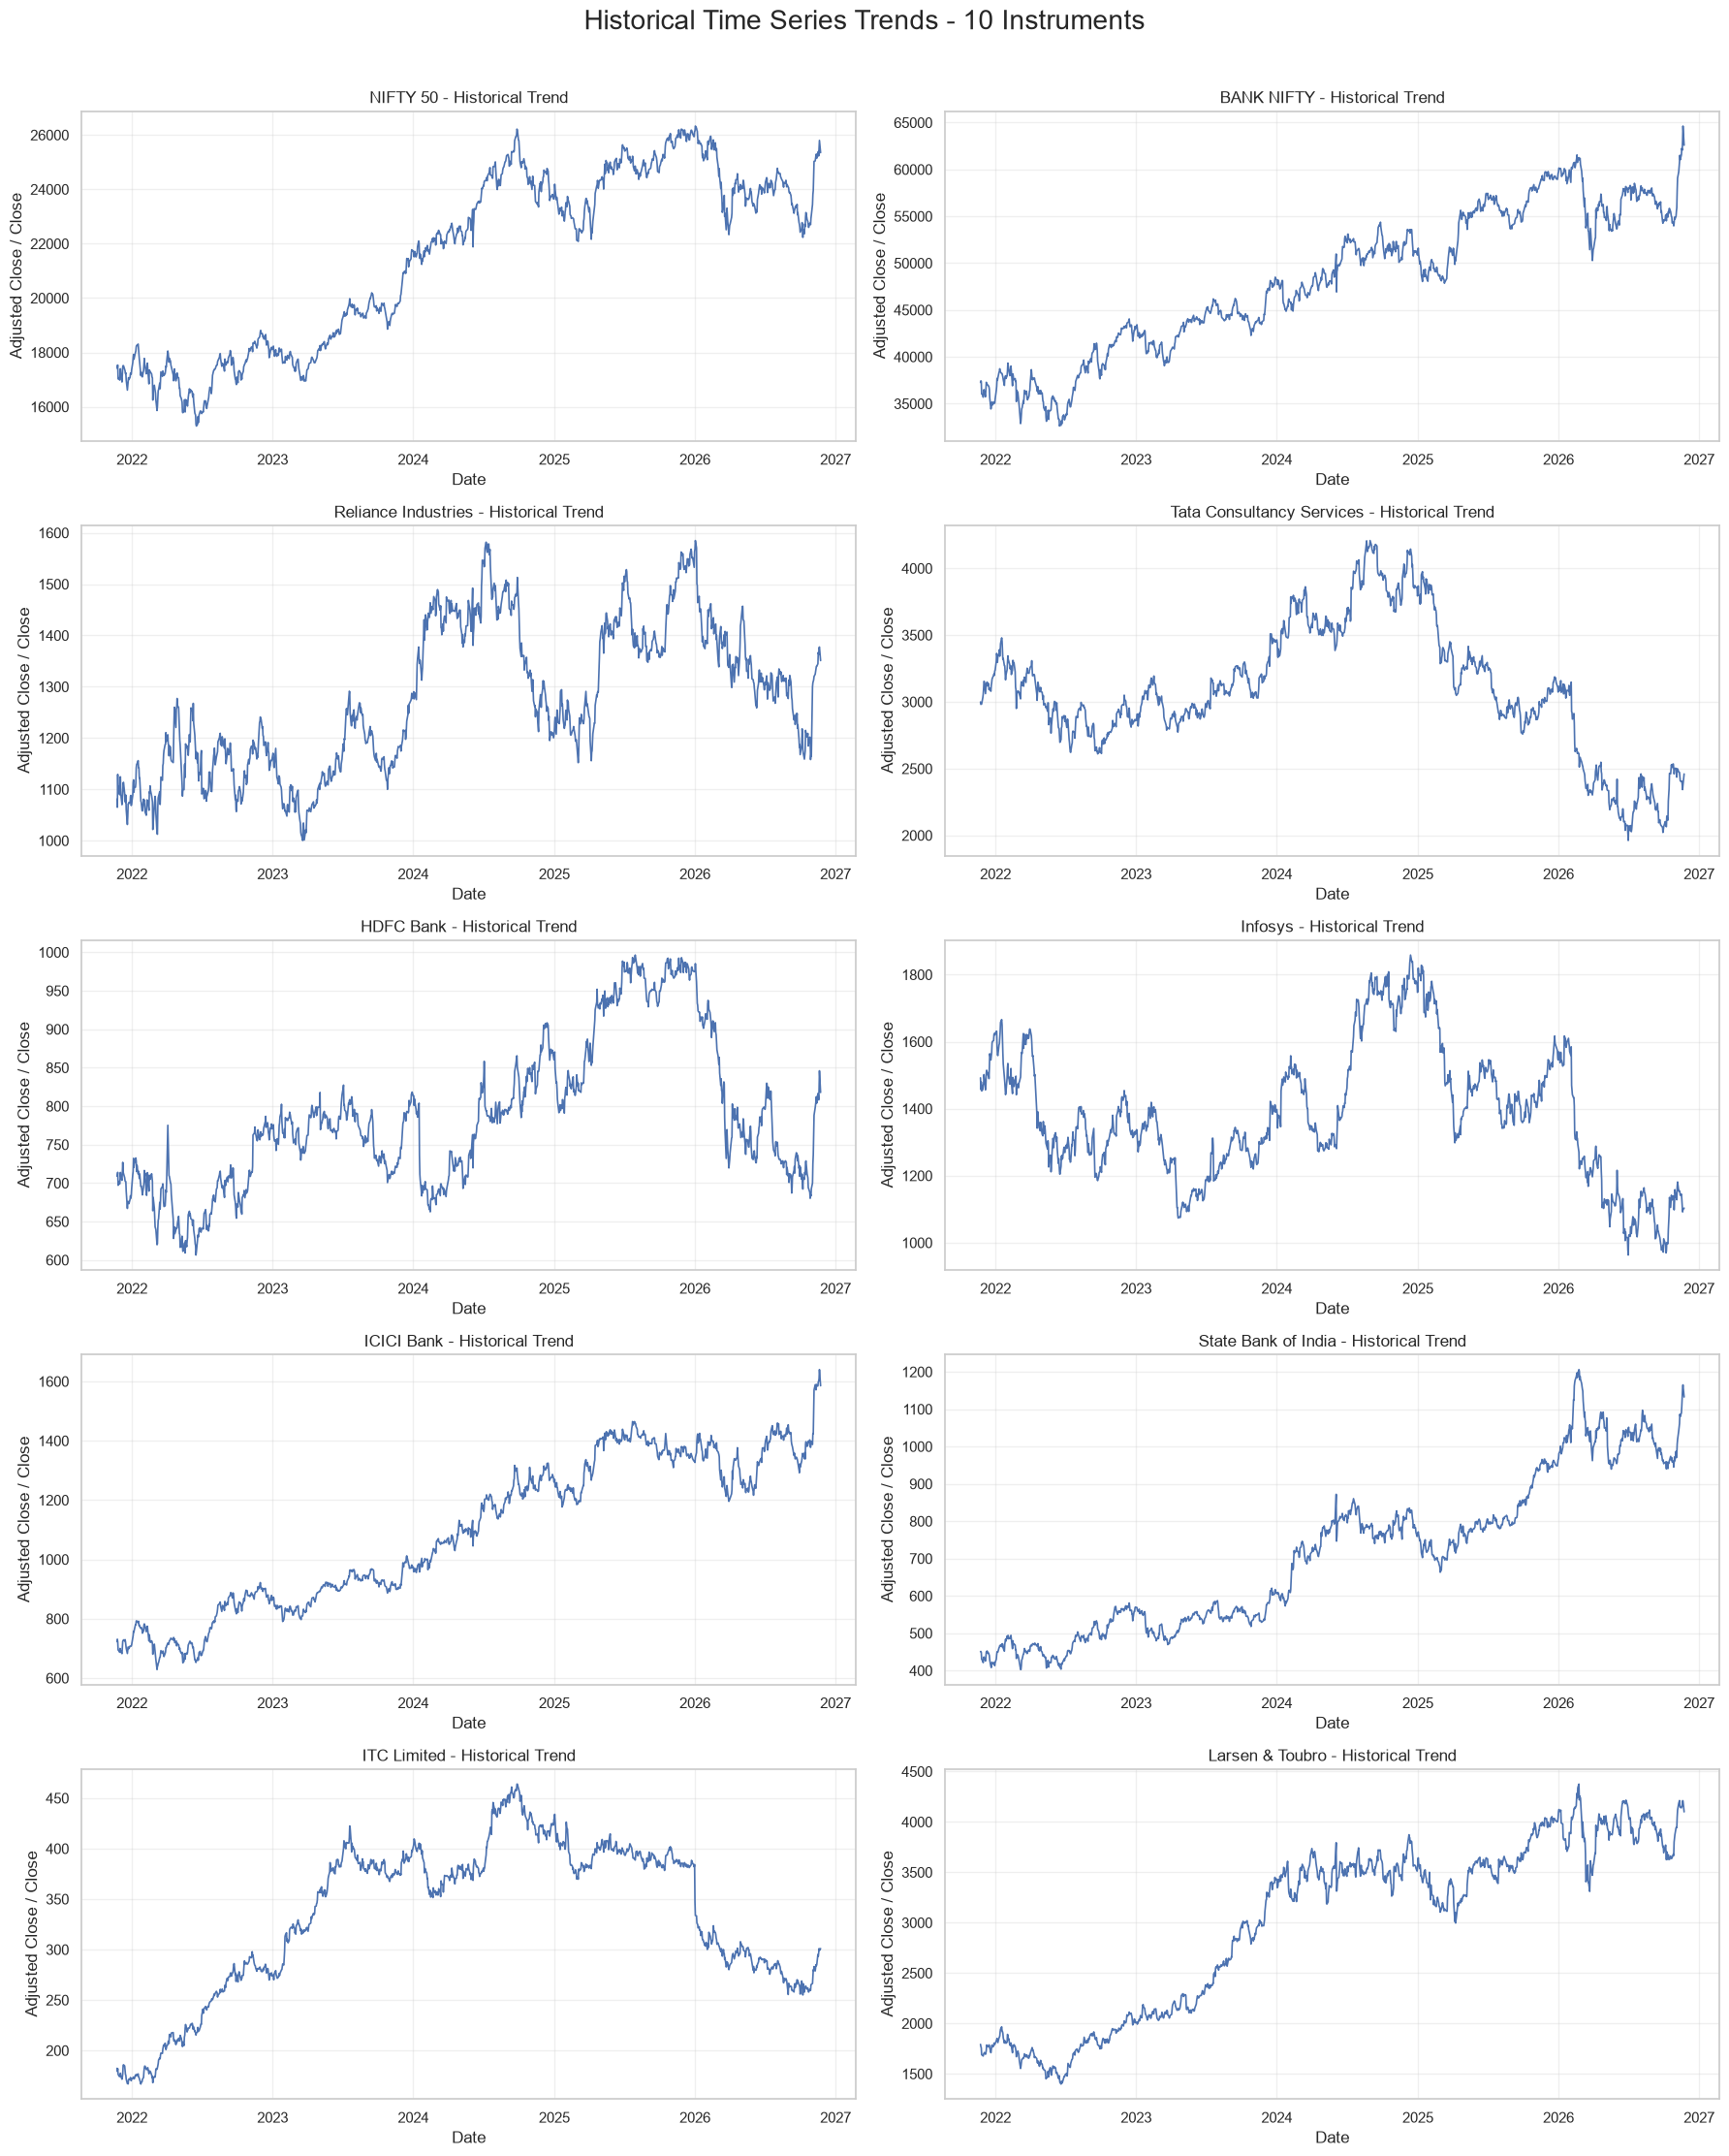

In [5]:
# ============================================
# CELL 5: HISTORICAL TREND ANALYSIS
# ============================================

fig, axes = plt.subplots(
    5, 2,
    figsize=(18, 22)
)

axes = axes.flatten()

for i, symbol in enumerate(price_series):

    series = price_series[symbol]

    axes[i].plot(
        series.index,
        series.values,
        linewidth=1.2
    )

    axes[i].set_title(
        f"{INSTRUMENTS[symbol]} - Historical Trend"
    )

    axes[i].set_xlabel("Date")
    axes[i].set_ylabel("Adjusted Close / Close")

    axes[i].grid(alpha=0.3)

plt.suptitle(
    "Historical Time Series Trends - 10 Instruments",
    fontsize=20,
    y=1.01
)

plt.tight_layout()

plt.savefig(
    CHART_DIR / "time_series_historical_trends.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

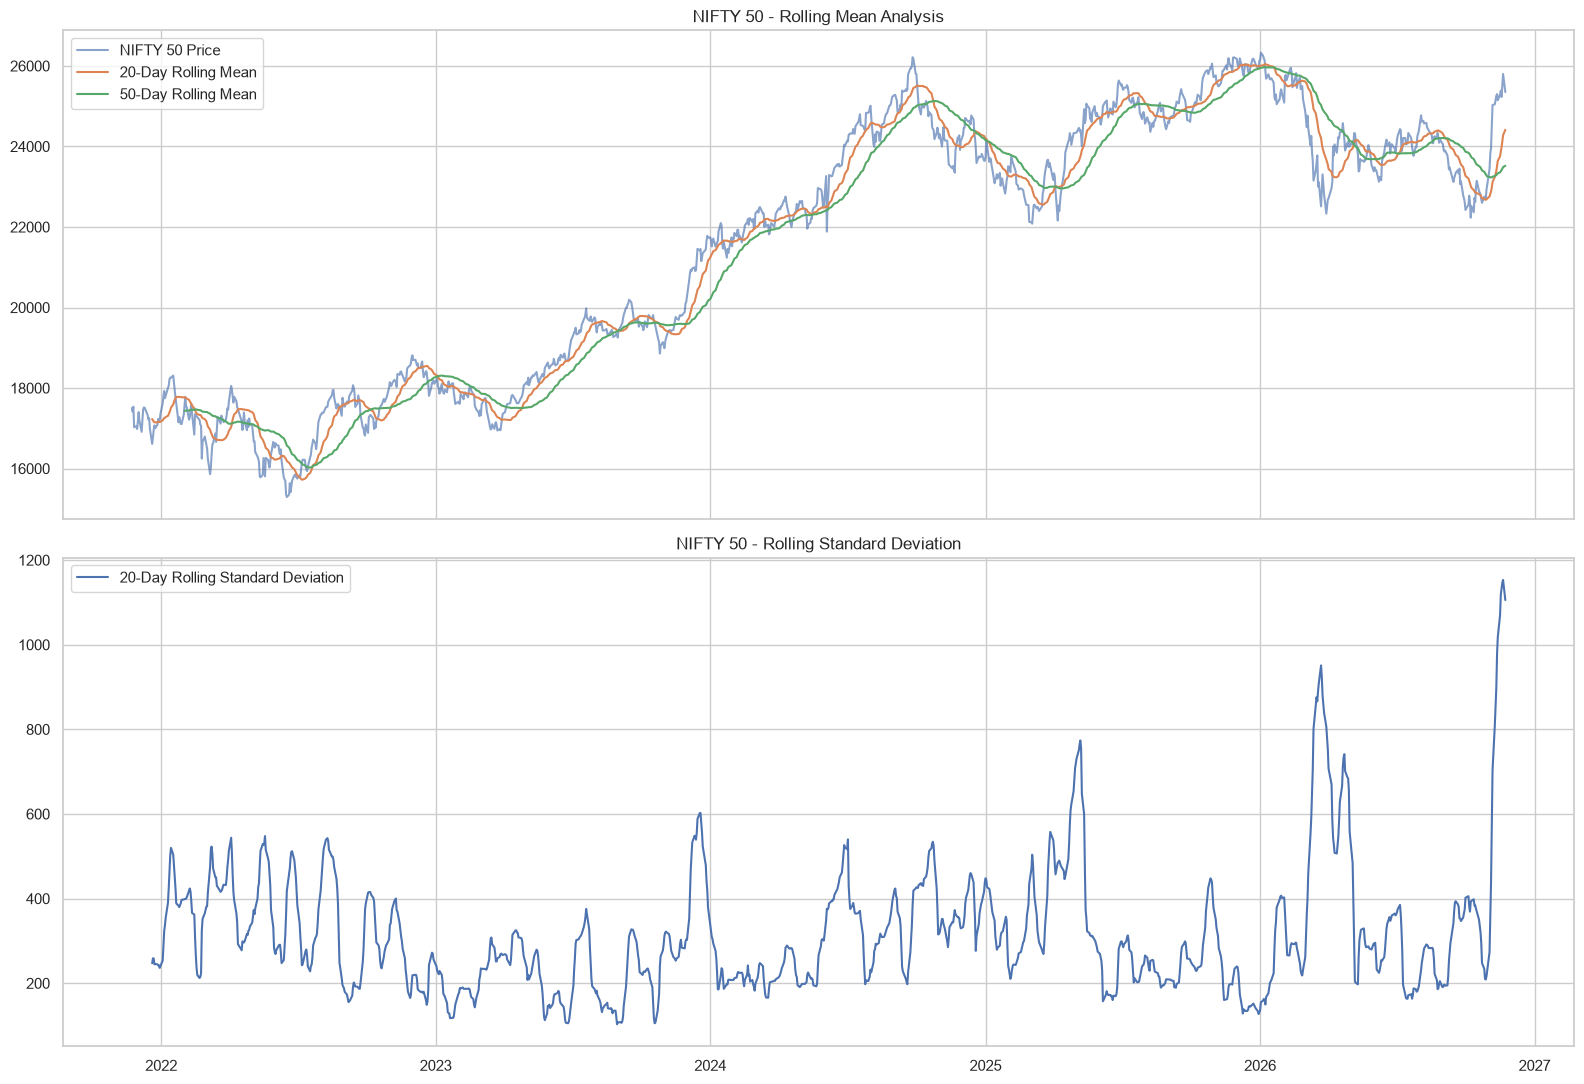

In [6]:
# ============================================
# CELL 6: ROLLING STATISTICS
# ============================================

symbol = "NIFTY50"

nifty_price = price_series[symbol]

rolling_mean_20 = nifty_price.rolling(20).mean()
rolling_mean_50 = nifty_price.rolling(50).mean()
rolling_std_20 = nifty_price.rolling(20).std()

fig, axes = plt.subplots(
    2, 1,
    figsize=(16, 11),
    sharex=True
)

axes[0].plot(
    nifty_price.index,
    nifty_price,
    label="NIFTY 50 Price",
    alpha=0.65
)

axes[0].plot(
    rolling_mean_20.index,
    rolling_mean_20,
    label="20-Day Rolling Mean"
)

axes[0].plot(
    rolling_mean_50.index,
    rolling_mean_50,
    label="50-Day Rolling Mean"
)

axes[0].set_title("NIFTY 50 - Rolling Mean Analysis")
axes[0].legend()

axes[1].plot(
    rolling_std_20.index,
    rolling_std_20,
    label="20-Day Rolling Standard Deviation"
)

axes[1].set_title("NIFTY 50 - Rolling Standard Deviation")
axes[1].legend()

plt.tight_layout()

plt.savefig(
    CHART_DIR / "nifty50_rolling_statistics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

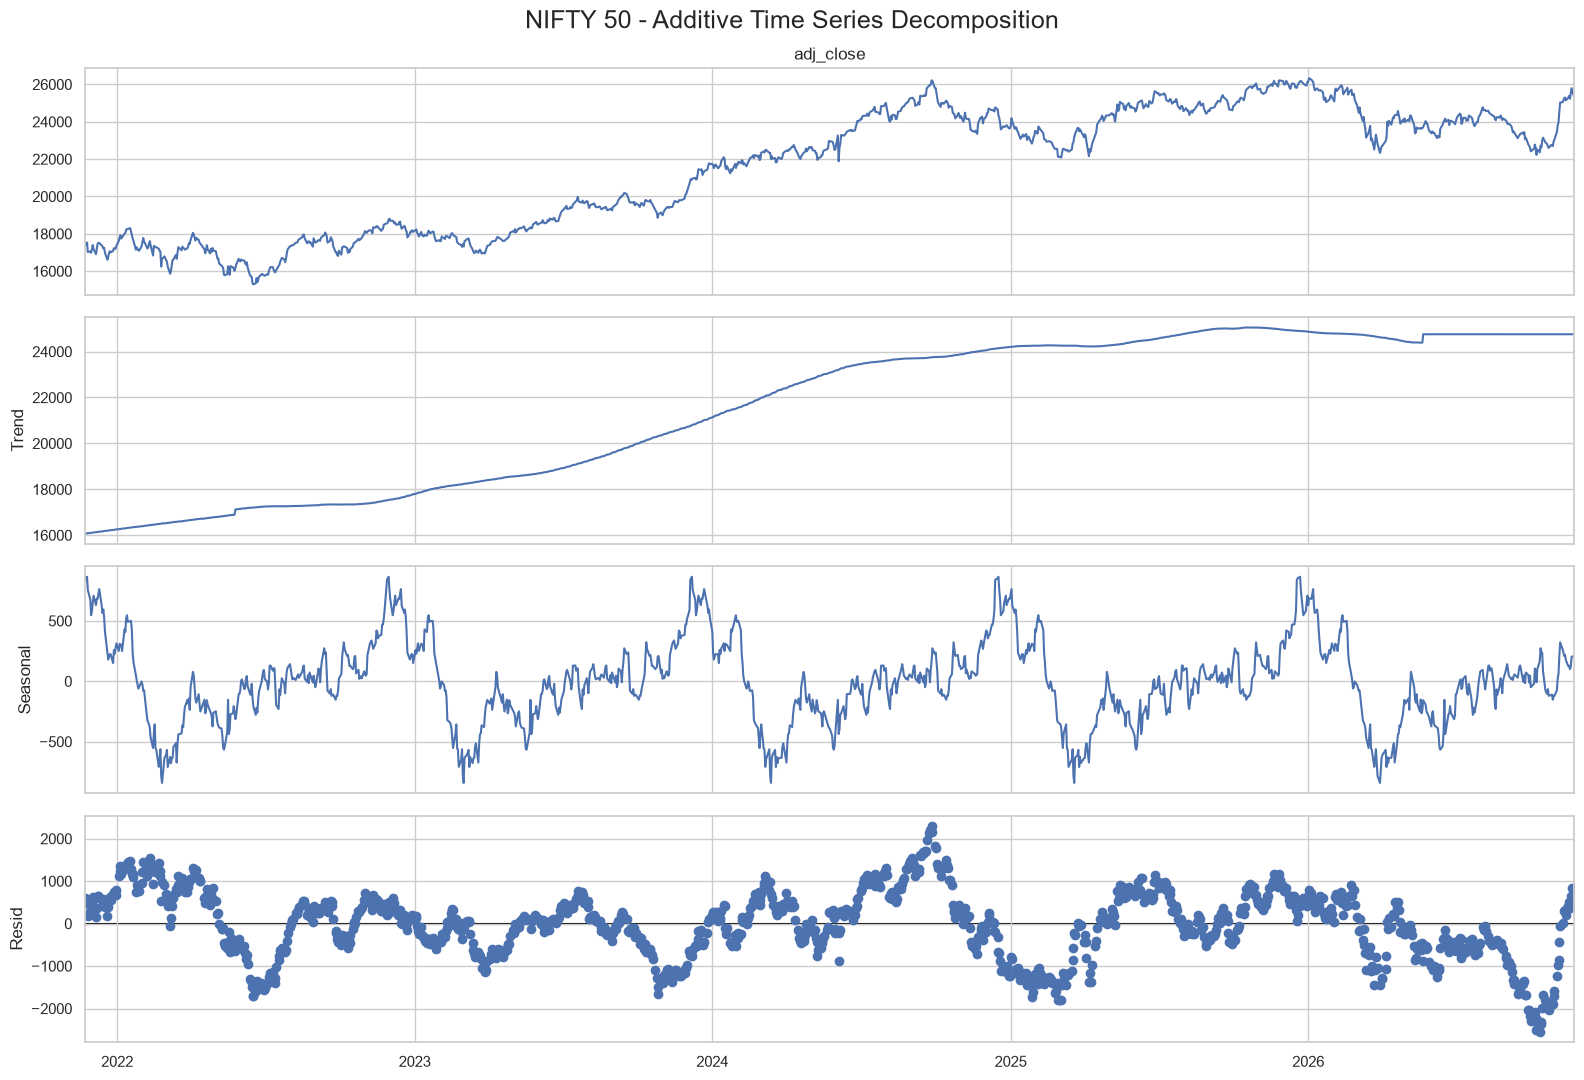

In [7]:
# ============================================
# CELL 7: ADDITIVE DECOMPOSITION
# ============================================

symbol = "NIFTY50"

nifty_price = price_series[symbol].copy()

# Ensure a regular trading-observation sequence.
# Do not insert artificial prices for missing market sessions.
nifty_price = nifty_price.dropna()

SEASONAL_PERIOD = 252

if len(nifty_price) >= 2 * SEASONAL_PERIOD:

    additive_result = seasonal_decompose(
        nifty_price,
        model="additive",
        period=SEASONAL_PERIOD,
        extrapolate_trend="freq"
    )

    fig = additive_result.plot()

    fig.set_size_inches(16, 11)

    fig.suptitle(
        "NIFTY 50 - Additive Time Series Decomposition",
        fontsize=18
    )

    plt.tight_layout()

    plt.savefig(
        CHART_DIR / "nifty50_additive_decomposition.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

else:

    print("Not enough observations for annual decomposition.")

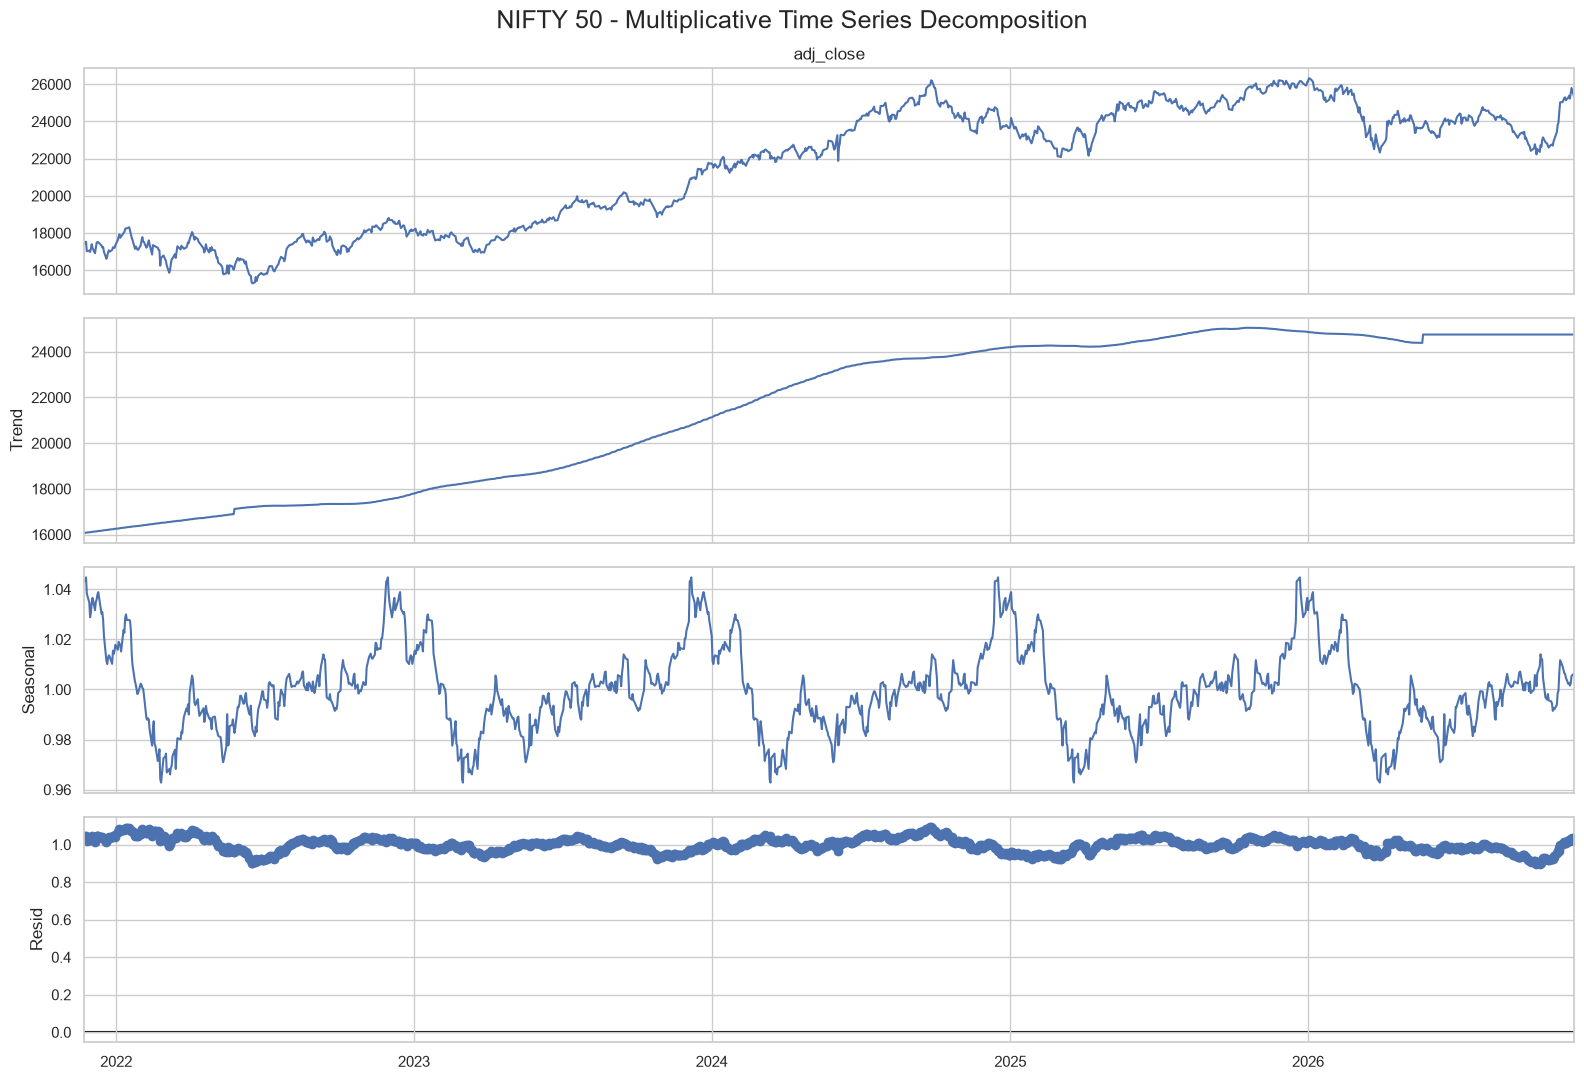

In [8]:
# ============================================
# CELL 8: MULTIPLICATIVE DECOMPOSITION
# ============================================

nifty_price = price_series["NIFTY50"].dropna()

if (nifty_price > 0).all() and len(nifty_price) >= 504:

    multiplicative_result = seasonal_decompose(
        nifty_price,
        model="multiplicative",
        period=252,
        extrapolate_trend="freq"
    )

    fig = multiplicative_result.plot()

    fig.set_size_inches(16, 11)

    fig.suptitle(
        "NIFTY 50 - Multiplicative Time Series Decomposition",
        fontsize=18
    )

    plt.tight_layout()

    plt.savefig(
        CHART_DIR / "nifty50_multiplicative_decomposition.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

else:

    print("Multiplicative decomposition requirements not satisfied.")

In [9]:
# ============================================
# CELL 9: ADF STATIONARITY TEST
# ============================================

def perform_adf_test(series, series_name):

    series = series.dropna()

    result = adfuller(
        series,
        autolag="AIC"
    )

    return {
        "Instrument": series_name,
        "Observations": len(series),
        "ADF Statistic": result[0],
        "p-value": result[1],
        "Lags Used": result[2],
        "Critical Value 1%": result[4]["1%"],
        "Critical Value 5%": result[4]["5%"],
        "Critical Value 10%": result[4]["10%"],
        "Stationarity Result": (
            "Stationary"
            if result[1] < 0.05
            else "Non-stationary / inconclusive"
        )
    }

adf_results = []

for symbol in price_series:

    result = perform_adf_test(
        price_series[symbol],
        symbol + " Price"
    )

    adf_results.append(result)

    result = perform_adf_test(
        return_series[symbol],
        symbol + " Returns"
    )

    adf_results.append(result)

adf_df = pd.DataFrame(adf_results)

display(adf_df.round(5))

adf_df.to_csv(
    REPORT_DIR / "adf_stationarity_results.csv",
    index=False
)

,Instrument,Observations,ADF Statistic,p-value,Lags Used,Critical Value 1%,Critical Value 5%,Critical Value 10%,Stationarity Result
0,NIFTY50 Price,1236,-1.04143,0.73786,0,-3.43566,-2.86388,-2.56802,Non-stationary / inconclusive
1,NIFTY50 Returns,1235,-35.73618,0.00000,0,-3.43566,-2.86389,-2.56802,Stationary
2,BANKNIFTY Price,1235,-1.06501,0.72882,5,-3.43568,-2.86389,-2.56802,Non-stationary / inconclusive
3,BANKNIFTY Returns,1234,-15.88837,0.00000,3,-3.43568,-2.86389,-2.56802,Stationary
4,RELIANCE Price,1237,-2.42783,0.13403,0,-3.43565,-2.86388,-2.56802,Non-stationary / inconclusive
5,RELIANCE Returns,1236,-34.96883,0.00000,0,-3.43566,-2.86388,-2.56802,Stationary
6,TCS Price,1237,-1.30478,0.62698,0,-3.43565,-2.86388,-2.56802,Non-stationary / inconclusive
7,TCS Returns,1236,-35.09234,0.00000,0,-3.43566,-2.86388,-2.56802,Stationary
8,HDFCBANK Price,1237,-2.11549,0.23833,4,-3.43567,-2.86389,-2.56802,Non-stationary / inconclusive
9,HDFCBANK Returns,1236,-16.52009,0.00000,3,-3.43567,-2.86389,-2.56802,Stationary


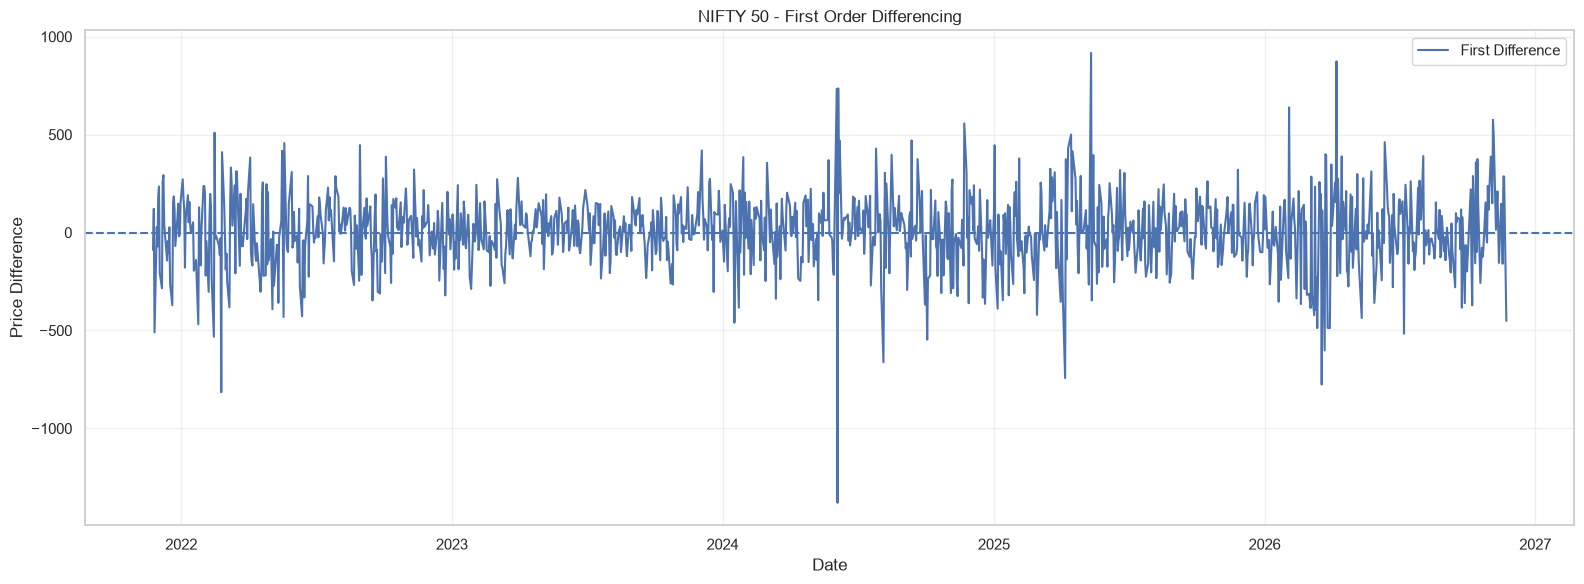

First differenced observations: 1235


In [10]:
# ============================================
# CELL 10: FIRST ORDER DIFFERENCING
# ============================================

nifty_price = price_series["NIFTY50"]

nifty_diff_1 = nifty_price.diff().dropna()

plt.figure(figsize=(16, 6))

plt.plot(
    nifty_diff_1.index,
    nifty_diff_1.values,
    label="First Difference"
)

plt.axhline(0, linestyle="--")

plt.title("NIFTY 50 - First Order Differencing")

plt.xlabel("Date")
plt.ylabel("Price Difference")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    CHART_DIR / "nifty50_first_difference.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "First differenced observations:",
    len(nifty_diff_1)
)

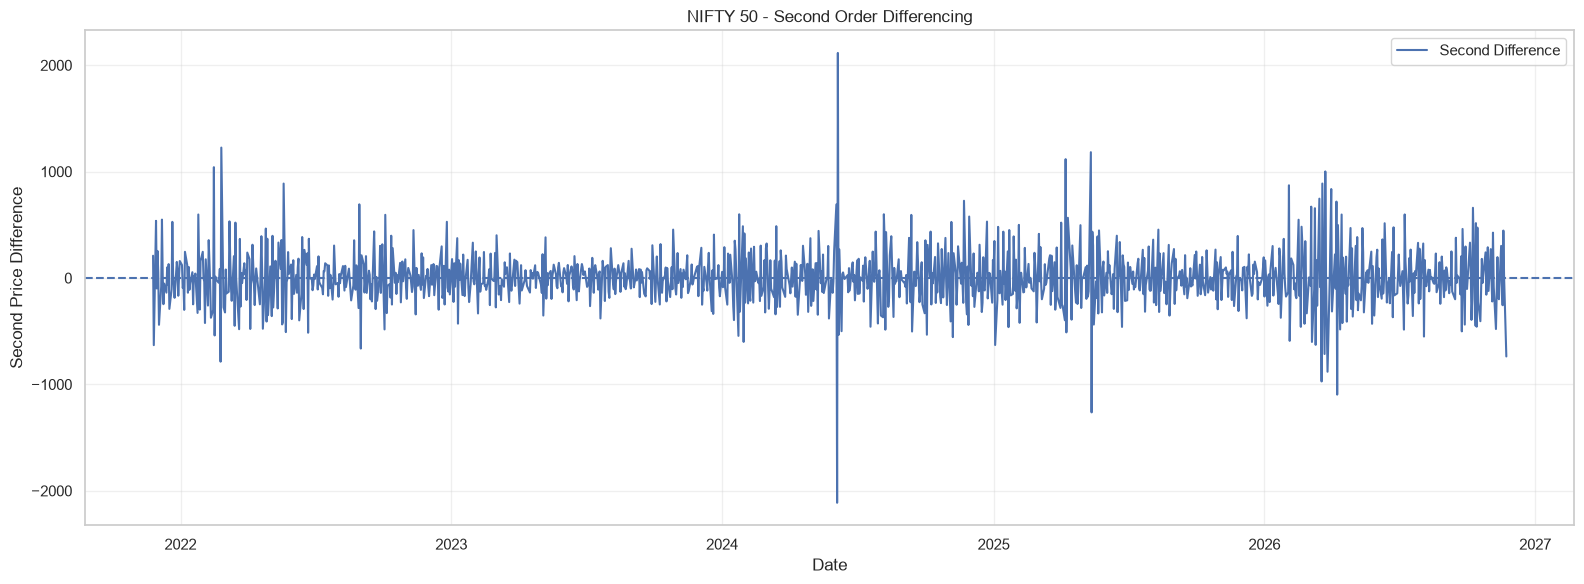

In [11]:
# ============================================
# CELL 11: SECOND ORDER DIFFERENCING
# ============================================

nifty_diff_2 = nifty_price.diff().diff().dropna()

plt.figure(figsize=(16, 6))

plt.plot(
    nifty_diff_2.index,
    nifty_diff_2.values,
    label="Second Difference"
)

plt.axhline(0, linestyle="--")

plt.title("NIFTY 50 - Second Order Differencing")

plt.xlabel("Date")
plt.ylabel("Second Price Difference")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    CHART_DIR / "nifty50_second_difference.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [12]:
# ============================================
# CELL 12: STATIONARITY COMPARISON
# ============================================

stationarity_comparison = []

series_to_test = {
    "Original Price": nifty_price,
    "First Difference": nifty_diff_1,
    "Second Difference": nifty_diff_2,
    "Daily Returns": return_series["NIFTY50"]
}

for name, series in series_to_test.items():

    result = adfuller(
        series.dropna(),
        autolag="AIC"
    )

    stationarity_comparison.append({

        "Series": name,

        "ADF Statistic": result[0],

        "p-value": result[1],

        "Stationarity at 5%": (
            "Yes"
            if result[1] < 0.05
            else "No"
        )

    })

stationarity_df = pd.DataFrame(
    stationarity_comparison
)

display(stationarity_df.round(5))

stationarity_df.to_csv(
    REPORT_DIR / "nifty50_differencing_comparison.csv",
    index=False
)

,Series,ADF Statistic,p-value,Stationarity at 5%
0,Original Price,-1.04143,0.73786,No
1,First Difference,-24.21401,0.00000,Yes
2,Second Difference,-13.66013,0.00000,Yes
3,Daily Returns,-35.73618,0.00000,Yes


<Figure size 1400x600 with 0 Axes>

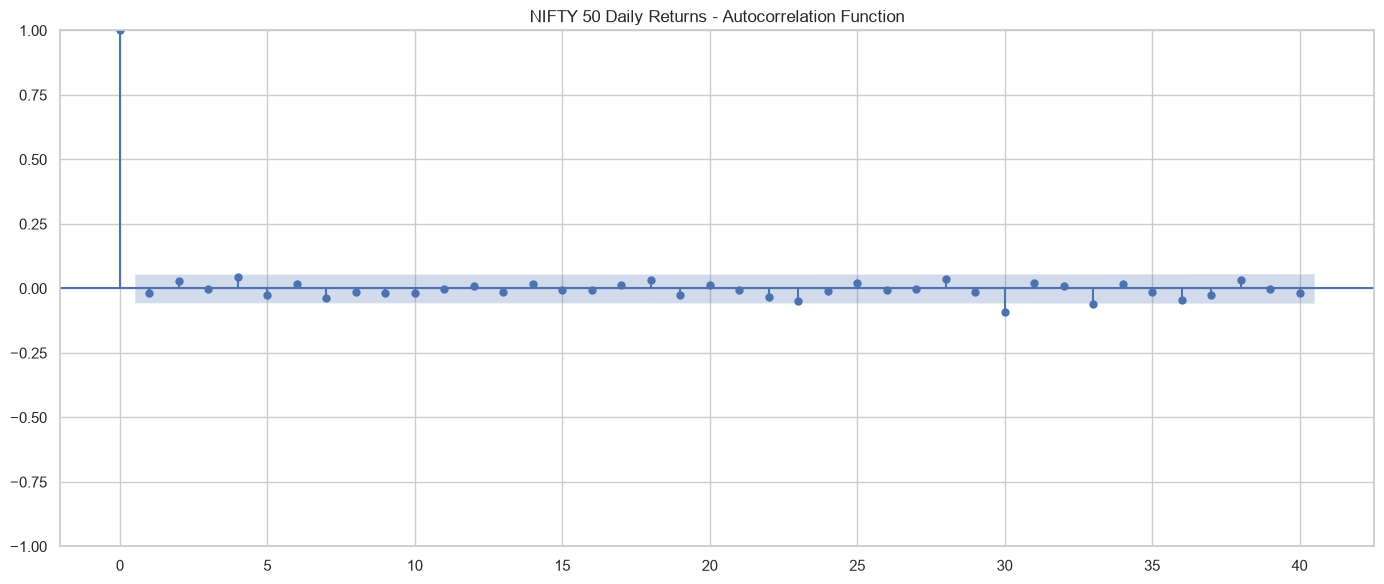

In [13]:
# ============================================
# CELL 13: AUTOCORRELATION FUNCTION
# ============================================

nifty_returns = return_series["NIFTY50"]

plt.figure(figsize=(14, 6))

plot_acf(
    nifty_returns,
    lags=40,
    alpha=0.05
)

plt.title(
    "NIFTY 50 Daily Returns - Autocorrelation Function"
)

plt.tight_layout()

plt.savefig(
    CHART_DIR / "nifty50_acf.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<Figure size 1400x600 with 0 Axes>

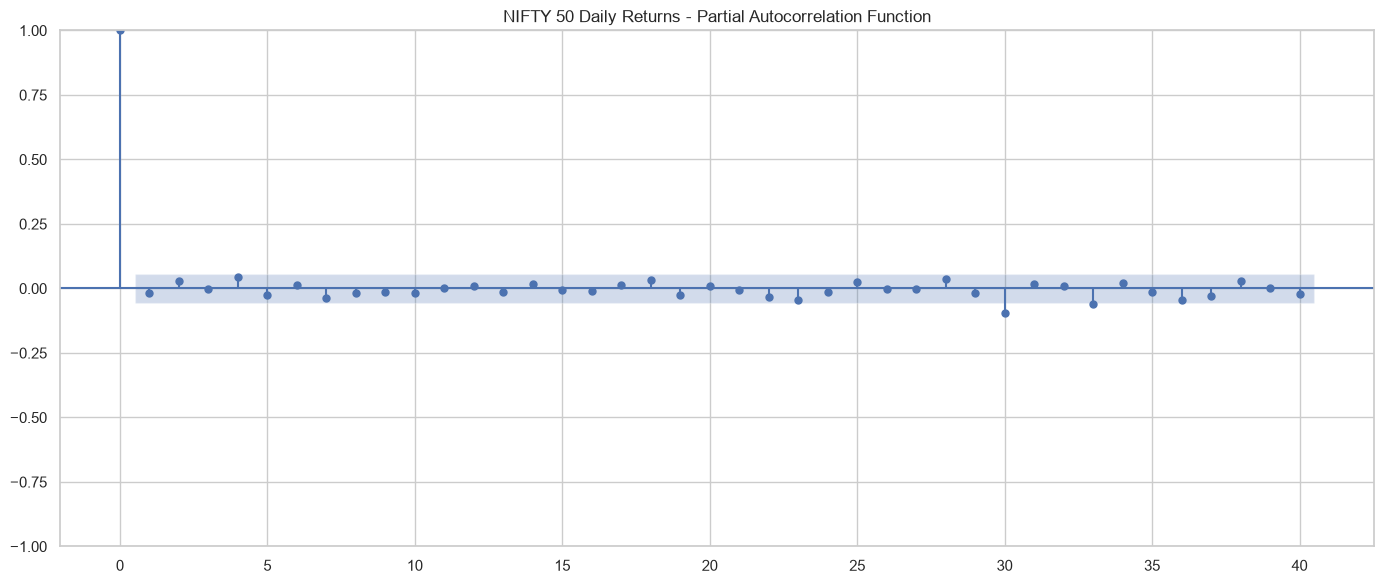

In [14]:
# ============================================
# CELL 14: PARTIAL AUTOCORRELATION FUNCTION
# ============================================

plt.figure(figsize=(14, 6))

plot_pacf(
    nifty_returns,
    lags=40,
    method="ywm",
    alpha=0.05
)

plt.title(
    "NIFTY 50 Daily Returns - Partial Autocorrelation Function"
)

plt.tight_layout()

plt.savefig(
    CHART_DIR / "nifty50_pacf.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

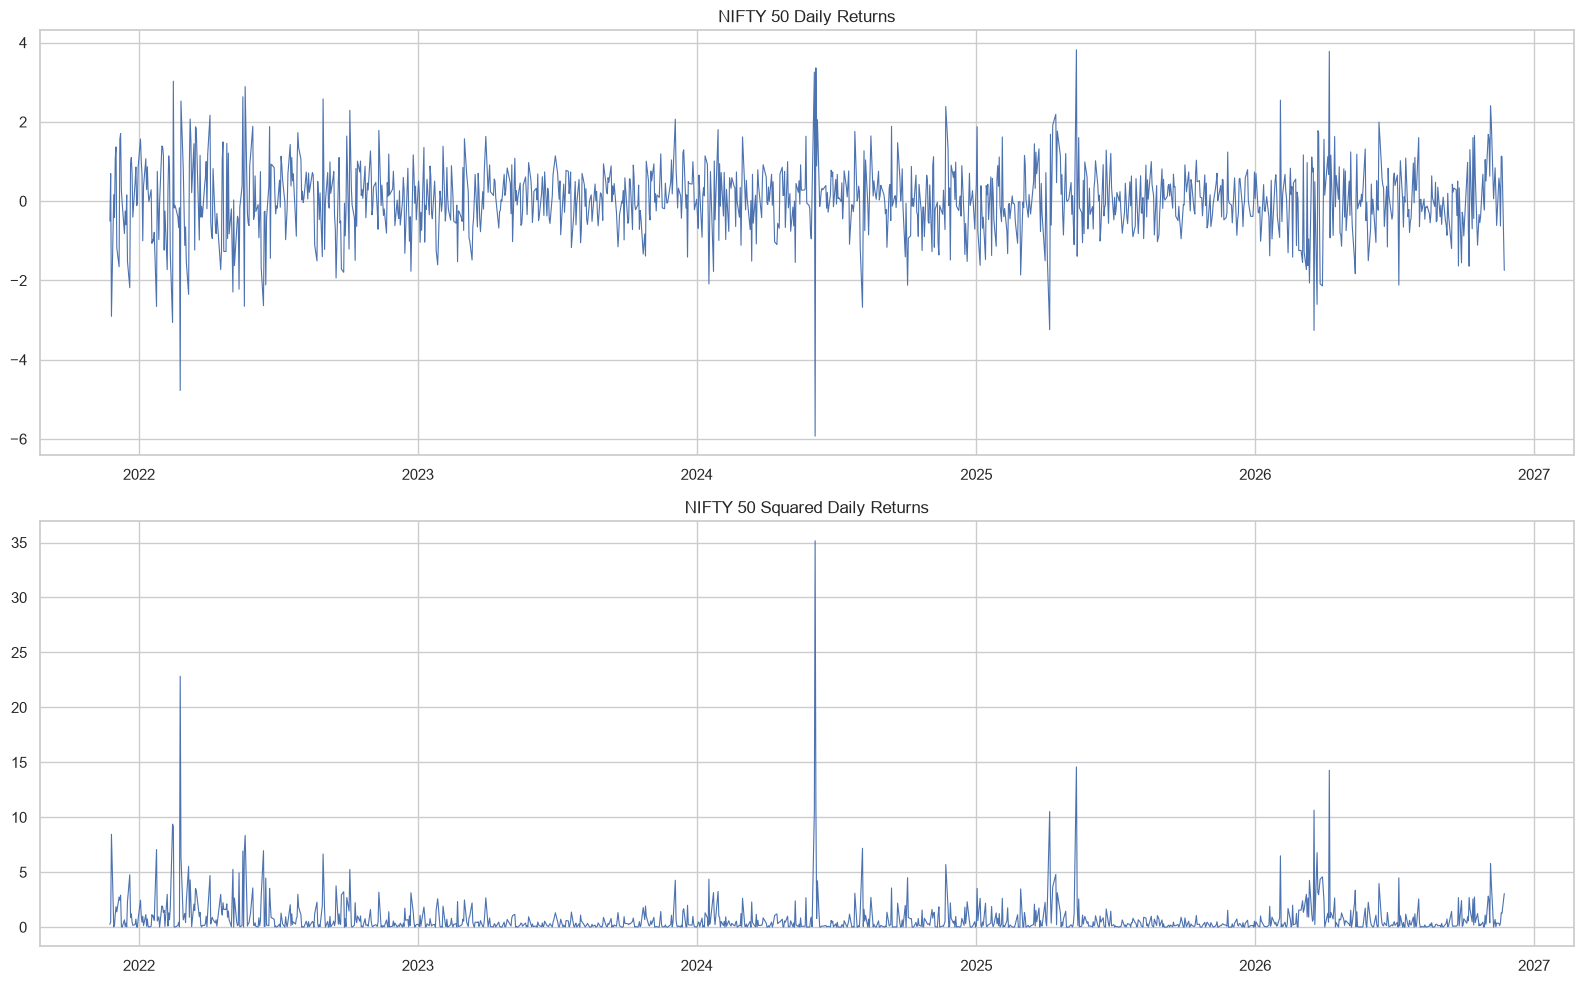

In [15]:
# ============================================
# CELL 15: VOLATILITY CLUSTERING
# ============================================

nifty_returns = return_series["NIFTY50"]

squared_returns = nifty_returns ** 2

fig, axes = plt.subplots(
    2, 1,
    figsize=(16, 10)
)

axes[0].plot(
    nifty_returns.index,
    nifty_returns,
    linewidth=0.8
)

axes[0].set_title("NIFTY 50 Daily Returns")

axes[1].plot(
    squared_returns.index,
    squared_returns,
    linewidth=0.8
)

axes[1].set_title("NIFTY 50 Squared Daily Returns")

plt.tight_layout()

plt.savefig(
    CHART_DIR / "nifty50_volatility_clustering.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<Figure size 1400x600 with 0 Axes>

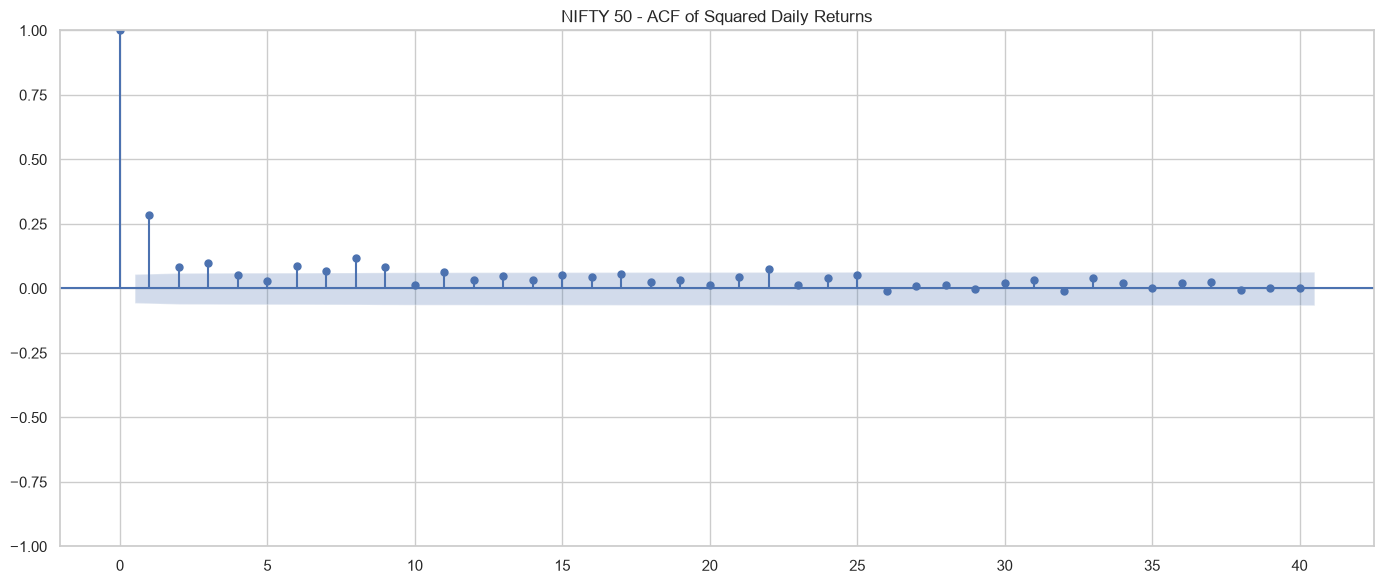

In [16]:
# ============================================
# CELL 16: SQUARED RETURN AUTOCORRELATION
# ============================================

plt.figure(figsize=(14, 6))

plot_acf(
    squared_returns.dropna(),
    lags=40,
    alpha=0.05
)

plt.title(
    "NIFTY 50 - ACF of Squared Daily Returns"
)

plt.tight_layout()

plt.savefig(
    CHART_DIR / "nifty50_squared_returns_acf.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
# ============================================
# CELL 17: ALL-INSTRUMENT STATIONARITY
# ============================================

all_stationarity = []

for symbol in INSTRUMENTS:

    for series_type, series in [
        ("Price", price_series[symbol]),
        ("Daily Returns", return_series[symbol])
    ]:

        result = adfuller(
            series.dropna(),
            autolag="AIC"
        )

        all_stationarity.append({

            "Symbol": symbol,

            "Series Type": series_type,

            "ADF Statistic": result[0],

            "p-value": result[1],

            "Stationarity at 5%": (
                "Stationary"
                if result[1] < 0.05
                else "Non-stationary / inconclusive"
            )

        })

all_stationarity_df = pd.DataFrame(
    all_stationarity
)

display(all_stationarity_df.round(5))

all_stationarity_df.to_csv(
    REPORT_DIR / "all_instruments_stationarity.csv",
    index=False
)

,Symbol,Series Type,ADF Statistic,p-value,Stationarity at 5%
0,NIFTY50,Price,-1.04143,0.73786,Non-stationary / inconclusive
1,NIFTY50,Daily Returns,-35.73618,0.00000,Stationary
2,BANKNIFTY,Price,-1.06501,0.72882,Non-stationary / inconclusive
3,BANKNIFTY,Daily Returns,-15.88837,0.00000,Stationary
4,RELIANCE,Price,-2.42783,0.13403,Non-stationary / inconclusive
5,RELIANCE,Daily Returns,-34.96883,0.00000,Stationary
6,TCS,Price,-1.30478,0.62698,Non-stationary / inconclusive
7,TCS,Daily Returns,-35.09234,0.00000,Stationary
8,HDFCBANK,Price,-2.11549,0.23833,Non-stationary / inconclusive
9,HDFCBANK,Daily Returns,-16.52009,0.00000,Stationary


In [18]:
# ============================================
# CELL 18: EXPORT DIFFERENCED SERIES
# ============================================

DIFFERENCED_DIR = (
    PROJECT_DIR / "data" / "stationary_series"
)

DIFFERENCED_DIR.mkdir(
    parents=True,
    exist_ok=True
)

for symbol in INSTRUMENTS:

    output_df = pd.DataFrame({

        "price": price_series[symbol],

        "daily_return": return_series[symbol],

        "first_difference": (
            price_series[symbol].diff()
        ),

        "second_difference": (
            price_series[symbol].diff().diff()
        )

    })

    output_df.to_csv(
        DIFFERENCED_DIR / f"{symbol}_stationarity.csv"
    )

print("Differenced datasets exported successfully!")

Differenced datasets exported successfully!


In [19]:
# ============================================
# CELL 19: FINAL REPORT
# ============================================

print("=" * 60)
print("BHARATMARKET AI")
print("NOTEBOOK 04 - TIME SERIES ANALYSIS")
print("=" * 60)

print("Instruments analysed:", len(market_data))

print("\nAnalysis completed:")

print("1. Historical trend analysis")
print("2. Rolling mean and standard deviation")
print("3. Additive decomposition")
print("4. Multiplicative decomposition")
print("5. Augmented Dickey-Fuller test")
print("6. First-order differencing")
print("7. Second-order differencing")
print("8. ACF analysis")
print("9. PACF analysis")
print("10. Volatility clustering")

print("\nReports saved in:", REPORT_DIR)

print("Charts saved in:", CHART_DIR)

print("=" * 60)
print("NOTEBOOK 04 COMPLETED")
print("=" * 60)

BHARATMARKET AI
NOTEBOOK 04 - TIME SERIES ANALYSIS
Instruments analysed: 10

Analysis completed:
1. Historical trend analysis
2. Rolling mean and standard deviation
3. Additive decomposition
4. Multiplicative decomposition
5. Augmented Dickey-Fuller test
6. First-order differencing
7. Second-order differencing
8. ACF analysis
9. PACF analysis
10. Volatility clustering

Reports saved in: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\outputs\reports
Charts saved in: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\outputs\charts
NOTEBOOK 04 COMPLETED
